In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [19]:
DATA_PATH = "../data/raw/students.csv"

df = pd.read_csv(DATA_PATH)

In [20]:
numerical_columns = df.select_dtypes(include=np.number).columns

print(numerical_columns)

Index(['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA',
       'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress',
       'Family_Support', 'Attendance_Rate'],
      dtype='str')


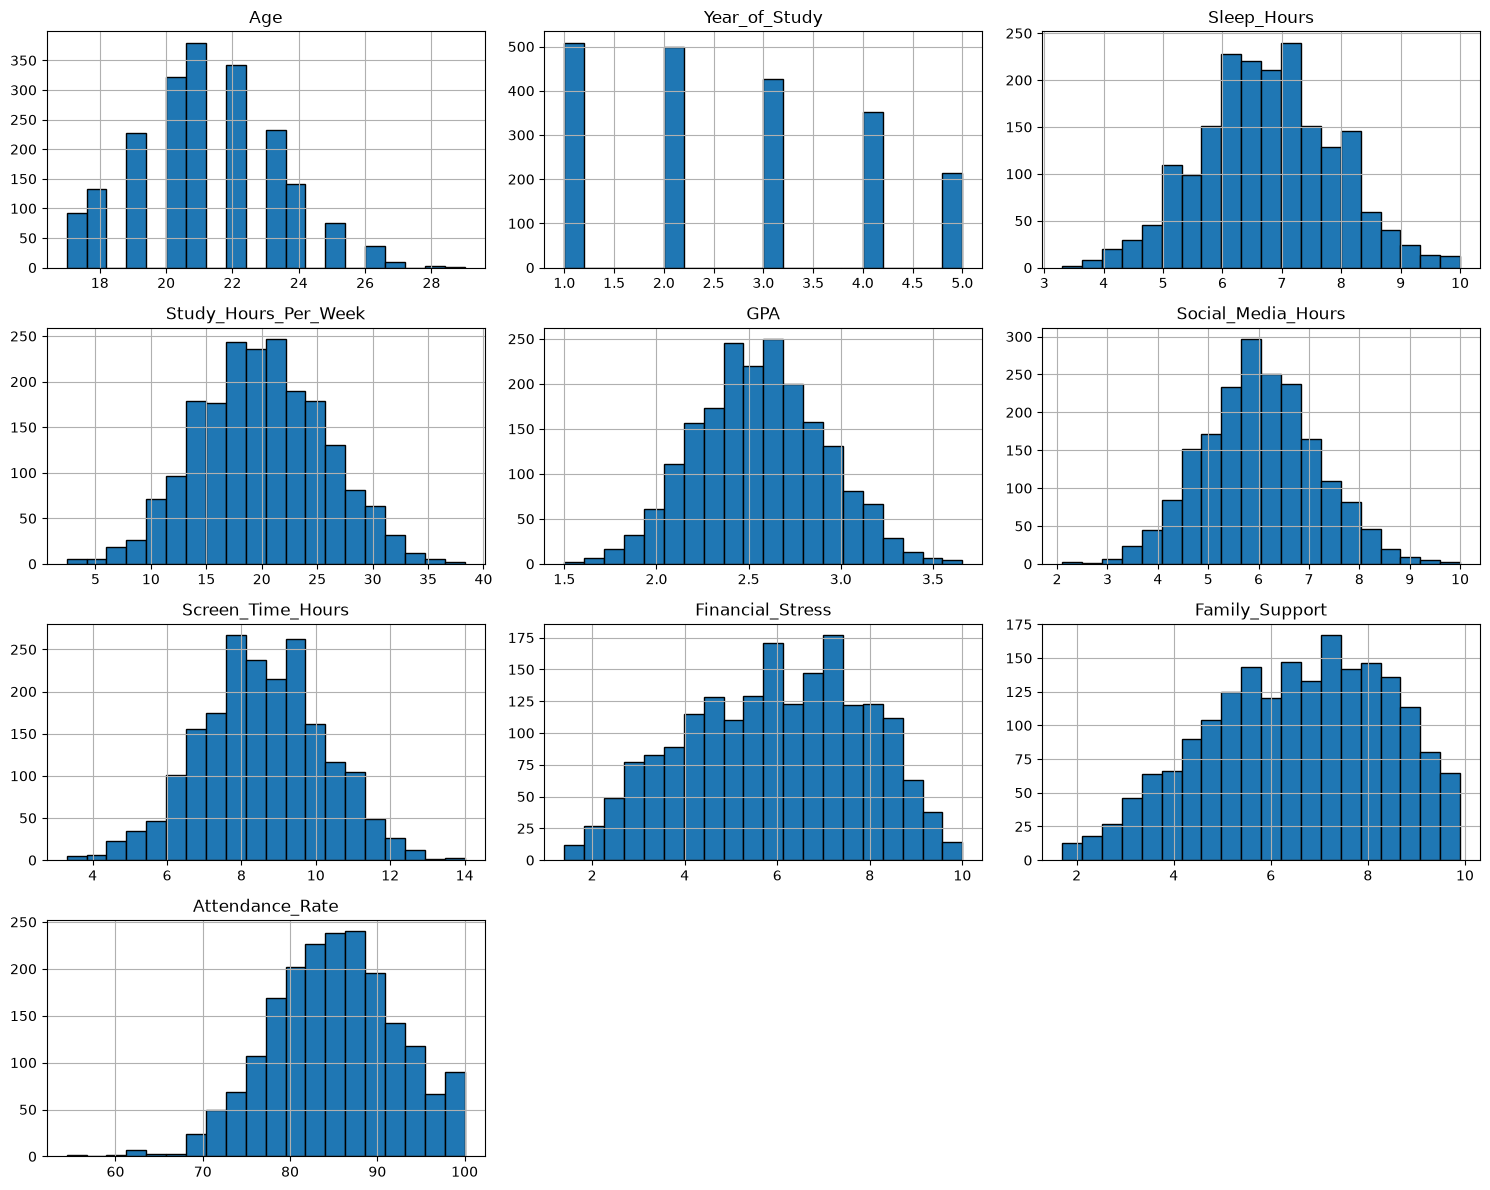

In [21]:
df[numerical_columns].hist(
    bins=20,
    figsize=(15, 12),
    edgecolor="black"
)

plt.tight_layout()
plt.show()

In [22]:
categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.drop('Student_ID')


print(categorical_columns)

Index(['Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality',
       'Previous_Mental_Health_History', 'Mental_Health_Risk'],
      dtype='str')


C:\Users\ycode\AppData\Local\Temp\ipykernel_34276\60716836.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


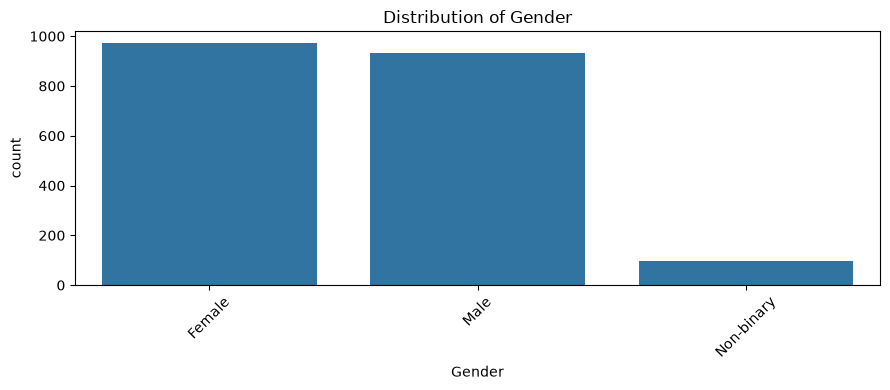

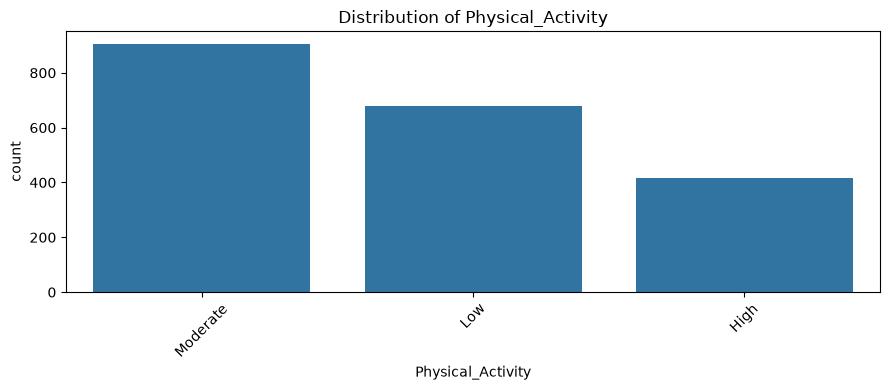

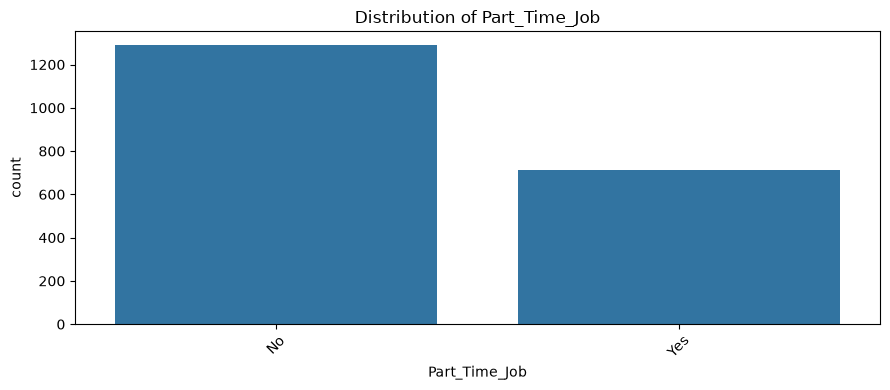

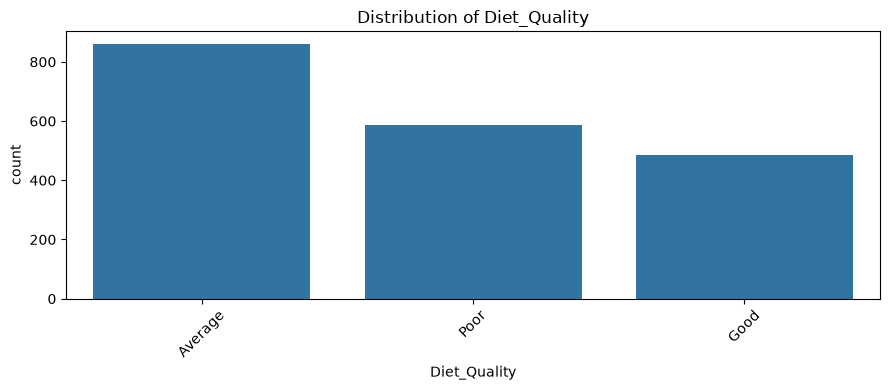

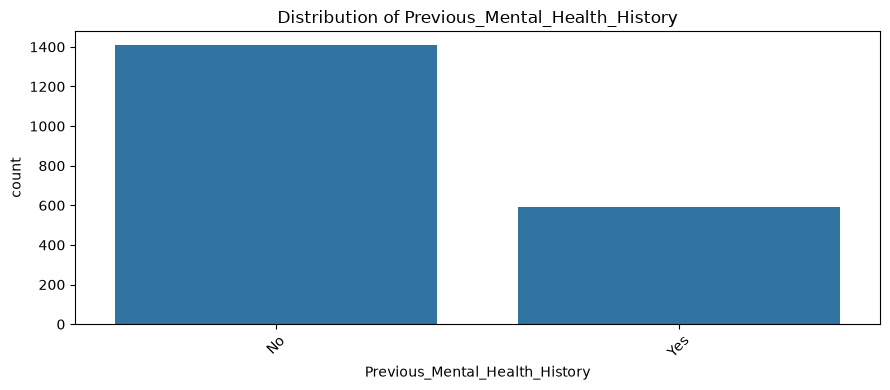

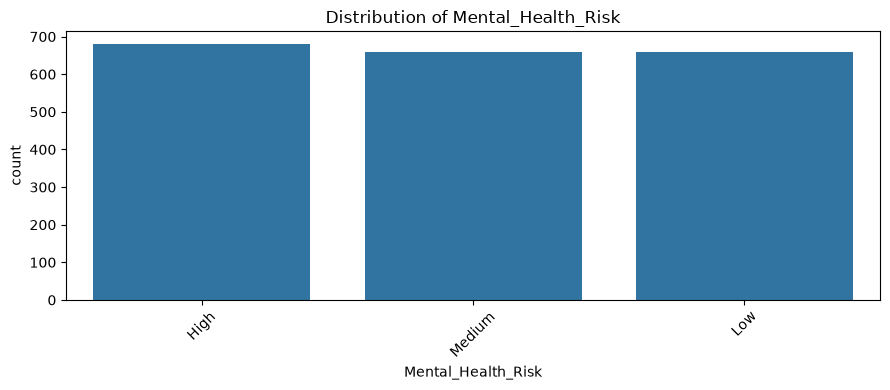

In [23]:
for column in categorical_columns:

    plt.figure(figsize=(9, 4))

    sns.countplot(
        data=df,
        x=column,
        order=df[column].value_counts().index
    )

    plt.title(f"Distribution of {column}")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [24]:
TARGET = "Mental_Health_Risk"

print("Unique values:")
print(df[TARGET].unique())

print("\nClass counts:")
print(df[TARGET].value_counts())

print("\nClass percentages:")
print(df[TARGET].value_counts(normalize=True) * 100)

Unique values:
<StringArray>
['High', 'Medium', 'Low']
Length: 3, dtype: str

Class counts:
Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64

Class percentages:
Mental_Health_Risk
High      34.0
Medium    33.0
Low       33.0
Name: proportion, dtype: float64


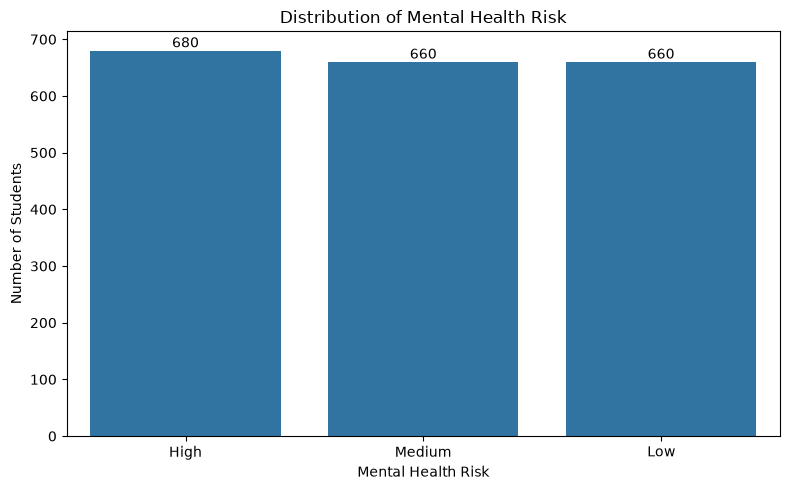

In [25]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x=TARGET,
    order=df[TARGET].value_counts().index
)

plt.title("Distribution of Mental Health Risk")
plt.xlabel("Mental Health Risk")
plt.ylabel("Number of Students")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

In [26]:
class_counts = df[TARGET].value_counts()

imbalance_ratio = class_counts.max() / class_counts.min()

print("Imbalance ratio:", round(imbalance_ratio, 2))

Imbalance ratio: 1.03


In [27]:
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()

categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()


if TARGET in numerical_columns:
    numerical_columns.remove(TARGET)

if TARGET in categorical_columns:
    categorical_columns.remove(TARGET)

print("Numerical features:", numerical_columns)
print("\nCategorical features:", categorical_columns)

Numerical features: ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']

Categorical features: ['Student_ID', 'Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History']


C:\Users\ycode\AppData\Local\Temp\ipykernel_34276\1353414747.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


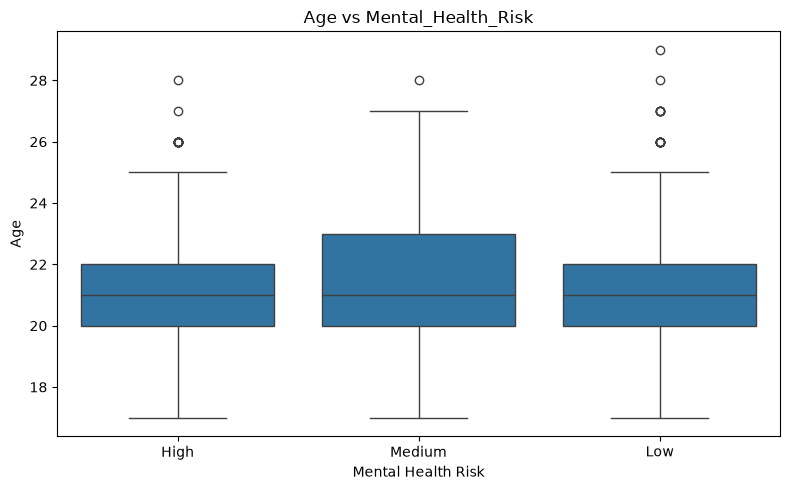

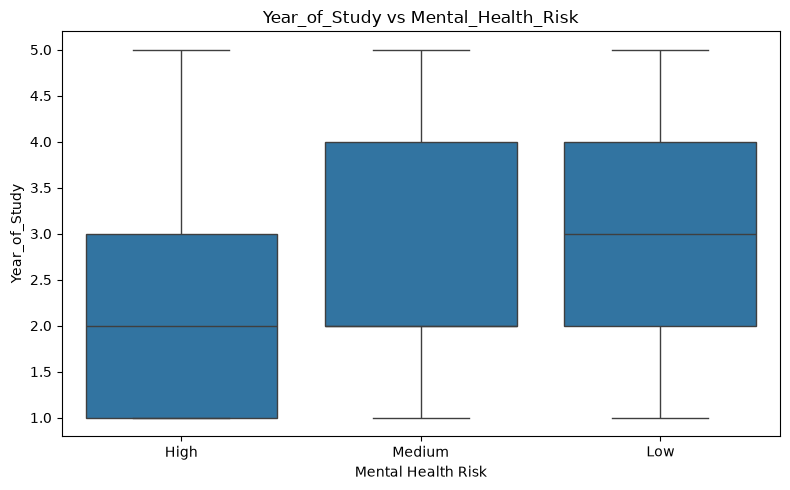

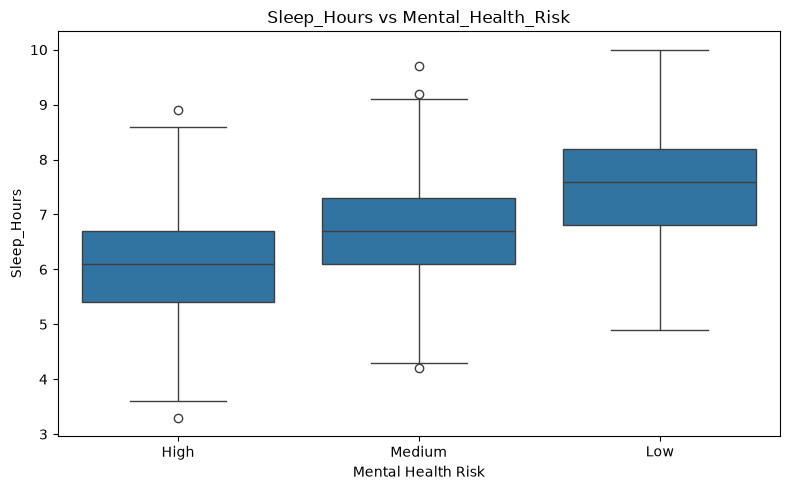

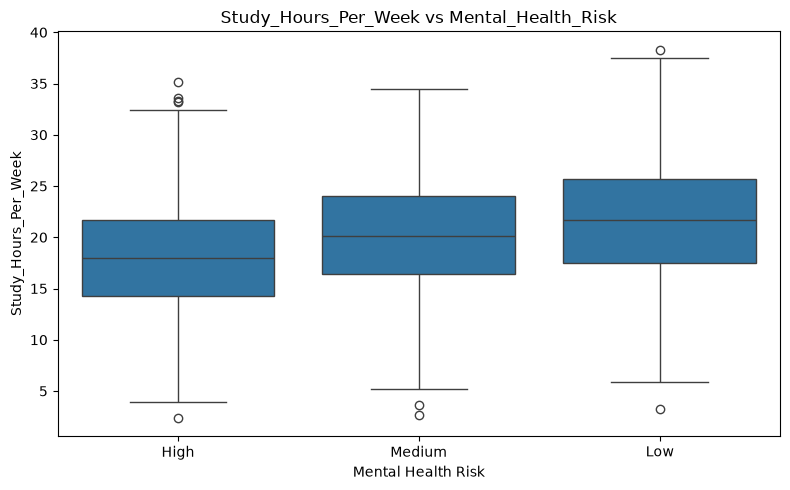

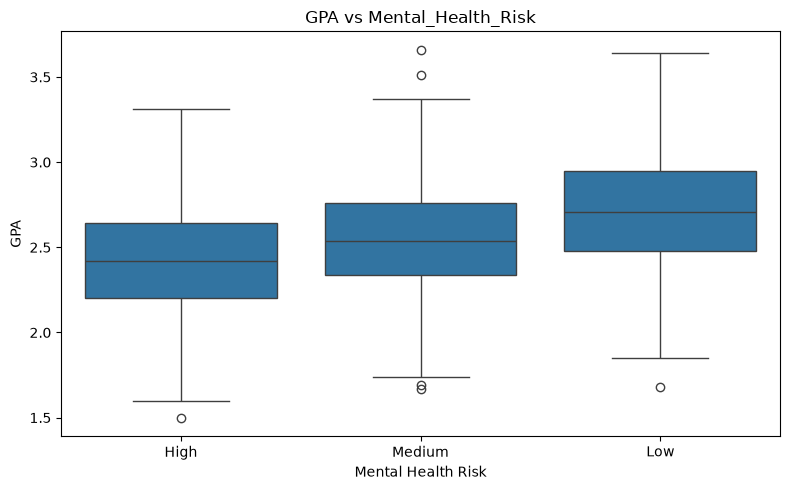

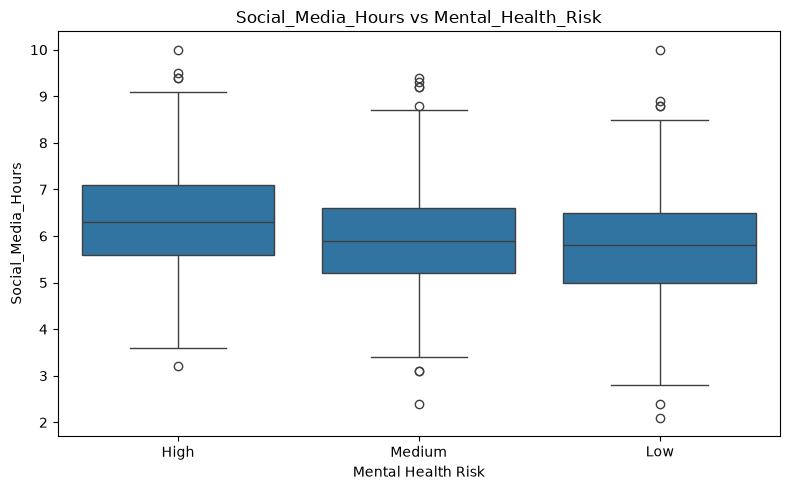

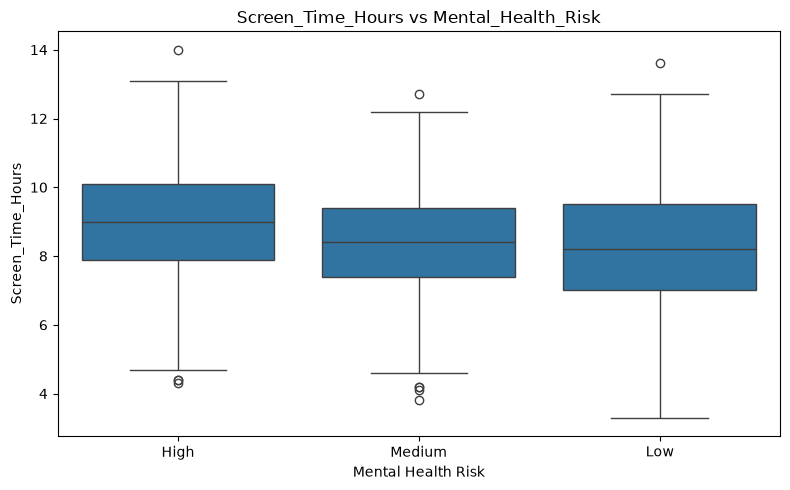

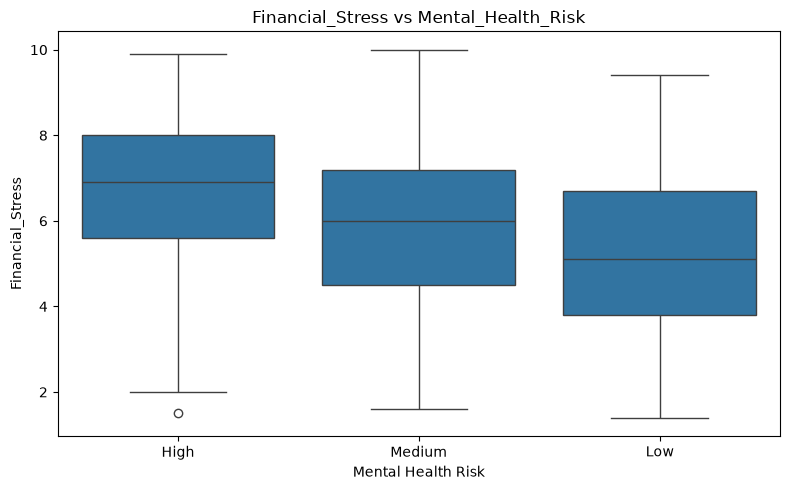

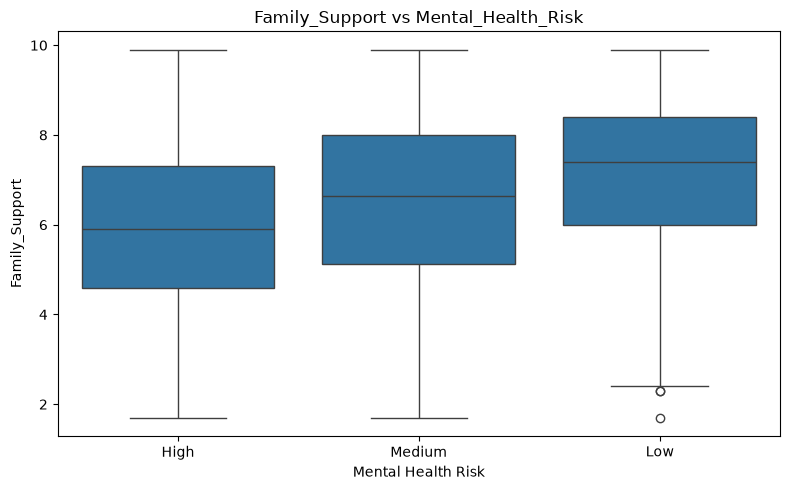

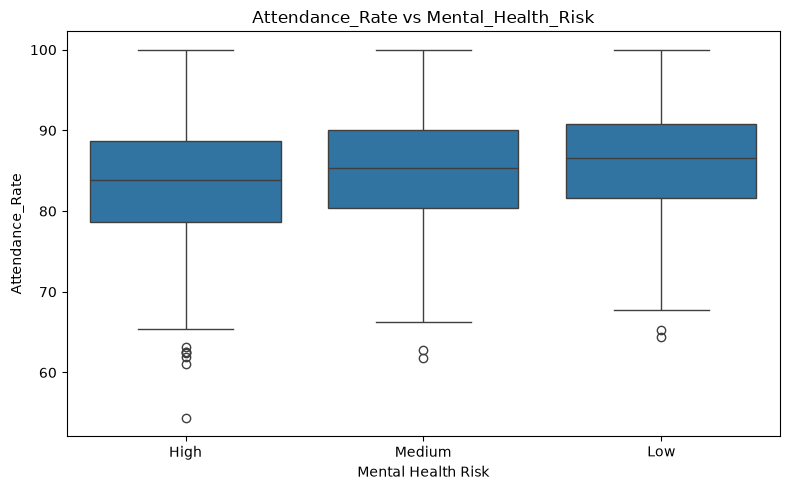

In [28]:
for column in numerical_columns:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x=TARGET,
        y=column
    )

    plt.title(f"{column} vs {TARGET}")
    plt.xlabel("Mental Health Risk")
    plt.ylabel(column)

    plt.tight_layout()
    plt.show()

In [29]:
correlation_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

correlation_columns.remove("Student_ID") if "Student_ID" in correlation_columns else None

correlation_matrix = df[correlation_columns].corr(method="pearson")

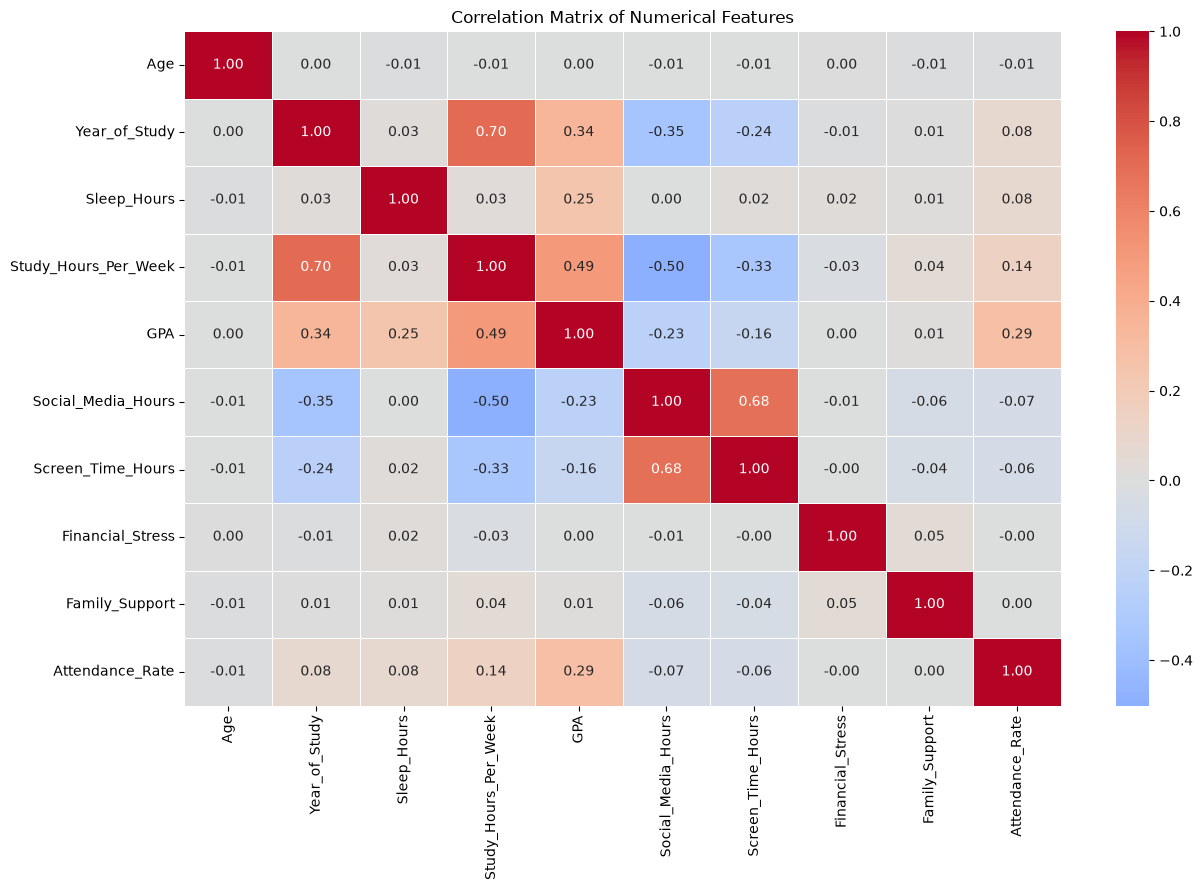

In [30]:
plt.figure(figsize=(13, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()